# 09 · Analysis: metrics, significance, files and diagrams

Plan section 6. Reads every run of the active experiment in `results/<experiment>/runs/` (v1, and v2 once it exists) and writes into `results/<experiment>/`:

* `run_metrics.parquet` (`run_id, index, level, metric, value, subset, n, ci_lo, ci_hi`) and `question_metrics.parquet` (per question, for the paired tests);
* `units/metrics.{csv,xlsx}` and `win500/metrics.{csv,xlsx}`: **one table per index**, to be merged by hand later;
* `granularity.csv`: RQ7, windows vs units;
* `diagrams/<run_id>.md`: Mermaid pipeline diagrams of hand-picked runs.

The experiment is set in `experiments.toml` (`active`, or `CSRAG_EXPERIMENT`); the first cell prints it. **Only answerable questions are scored**, and every metric table states its n. Tables are sorted by section-level nDCG@10 for readability only: every metric is reported and read, and no run is selected as the winner.

In [2]:
from pathlib import Path
import os, sys
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)  # all paths below are relative to the repo root
from dotenv import load_dotenv
load_dotenv(ROOT / ".env")
DATA = ROOT / "data"
from csrag import experiment
EXP = experiment.active()  # `active` in experiments.toml, or the CSRAG_EXPERIMENT environment variable
RESULTS = ROOT / EXP.dir   # results/<experiment name>/: every result of this experiment
print(EXP.summary())

experiment 'run2' -> results/run2/  (Question set 1 + question set 2 (paraphrase, section_id, twin_topic, multi_section))
   100  data/eval/questions.jsonl
   177  data/eval/set2/paraphrase.jsonl
    50  data/eval/set2/section_id.jsonl
    60  data/eval/set2/twin_topic.jsonl
    90  data/eval/set2/multi_section.jsonl
   477  questions, 469 answerable | qrels: results/run2/qrels.jsonl


In [3]:
import json
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from tqdm.auto import tqdm
from csrag import evaluate as ev, report as rp, runs
from csrag.corpus import Corpus
from csrag.retrievers.base import EXPANSION_METHODS, RANKED_METHODS

corpus = Corpus(DATA)
questions, problems = ev.load_questions(EXP.questions, corpus)
qrels = ev.read_qrels(EXP.qrels_path)
N_ANSWERABLE = sum(q["answerable"] for q in questions)
N_UNANSWERABLE = len(questions) - N_ANSWERABLE
assert {r["question_id"] for r in qrels} == {q["question_id"] for q in questions if q["answerable"]}, "qrels do not match the questions: run notebook 06"
run_ids = runs.list_runs()
stale = [r for r in run_ids if not runs.same_questions(r, questions)]
assert run_ids and not stale, f"no runs, or runs made with another question set, in {runs.runs_root()}: {stale[:5]}"
rt = ev.run_table(run_ids)
rt.groupby(["params_version", "index", "gate"]).size().rename("runs").to_frame().T

params_version    v1                   
index          units       win500      
gate           False True   False True 
runs              26    29     26    29

## Evaluate every run

In [4]:
pq, rm, gates, costs = ev.evaluate_all(run_ids, questions, qrels, corpus, progress=tqdm)
gate_overall = ev.gate_loss_vs_gate_off(pq, rt)
RESULTS.mkdir(parents=True, exist_ok=True)
rm.to_parquet(RESULTS / "run_metrics.parquet", index=False)
pq.to_parquet(RESULTS / "question_metrics.parquet", index=False)
# first_gold_rank is NaN when the gold is not retrieved, so it is the one metric with n < N_ANSWERABLE
scored = rm[(rm["subset"] == "all") & rm["level"].isin(["unit", "section", "group", "evidence"]) & (rm["metric"] != "first_gold_rank")]
assert (scored["n"] == N_ANSWERABLE).all(), "every scored metric row must cover every answerable question"
print(len(rm), "metric rows for", rm["run_id"].nunique(), "runs;", rp.n_note(questions))

evaluate:   0%|          | 0/110 [00:00<?, ?it/s]

61270 metric rows for 110 runs; n = 469 answerable; 8 unanswerable excluded


## Significance (pre-declared comparisons only)

Paired randomisation tests (sign flip, 10,000 permutations) on every metric. Holm correction within each RQ, metric and index (and params version). RQ1–RQ6 are tested within each index with matched gate and budget; RQ7 compares the two indexes with the gate off, at section/group level and on evidence recall. Everything else is descriptive.

In [5]:
qids = [q["question_id"] for q in questions if q["answerable"]]
sig = pd.concat([ev.significance(pq, rt, qids, index=i) for i in corpus.indexes()], ignore_index=True)
sig7 = ev.significance(pq, rt, qids, rq7=True)
key = (sig["level"] == "section") & (sig["metric"] == "ndcg@10")
sig[key][["rq", "a", "b", "index", "gate", "budget", "params_version", "mean_a", "mean_b", "diff", "diff_ci_lo",
          "diff_ci_hi", "p", "p_holm"]].round(4)

,rq,a,b,index,gate,budget,params_version,mean_a,mean_b,diff,diff_ci_lo,diff_ci_hi,p,p_holm
24,RQ1,S1,L1,units,False,NaN,v1,0.6421,0.6616,-0.0195,-0.0415,0.0024,0.0826,0.0826
69,RQ1,S1,L1,units,True,NaN,v1,0.6126,0.6417,-0.0291,-0.0527,-0.0059,0.0129,0.0258
114,RQ1,D1,L1,units,False,NaN,v1,0.7485,0.6616,0.0869,0.0569,0.1168,0.0001,0.0006
159,RQ1,D1,L1,units,True,NaN,v1,0.7261,0.6417,0.0844,0.0532,0.1159,0.0001,0.0006
204,RQ1,C1,L1,units,False,NaN,v1,0.7525,0.6616,0.0909,0.0621,0.1204,0.0001,0.0006
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4209,RQ6,T2+T3,T0,win500,False,8192.0,v1,0.7411,0.7392,0.0019,-0.0118,0.0154,0.7923,1.0000
4254,RQ6,T2+T3,T0,win500,True,8192.0,v1,0.7572,0.7429,0.0142,0.0002,0.0283,0.0495,0.4950
4299,RQ6,T4,T2+T3,win500,True,16384.0,v1,0.8663,0.7604,0.1059,0.0795,0.1333,0.0001,0.0021
4344,RQ6,T4,T2+T3,win500,True,4096.0,v1,0.8563,0.7483,0.1080,0.0806,0.1361,0.0001,0.0021


## Write the metrics files

In [6]:
written = {i: rp.write_index_files(i, rm, pq, rt, gates, costs, gate_overall, sig, questions, corpus) for i in corpus.indexes()}
rp.write_granularity(sig7, RESULTS / "granularity.csv")
written

{'units': {'csv': PosixPath('results/run2/units/metrics.csv'),
  'xlsx': PosixPath('results/run2/units/metrics.xlsx'),
  'runs': 55},
 'win500': {'csv': PosixPath('results/run2/win500/metrics.csv'),
  'xlsx': PosixPath('results/run2/win500/metrics.xlsx'),
  'runs': 55}}

## Tables by research question

Key columns only; the CSV/XLSX files hold every metric.

In [7]:
tables = {i: pd.read_csv(RESULTS / i / "metrics.csv") for i in corpus.indexes()}
COLS = ["method", "gate", "budget", "section_ndcg@10", "section_ndcg@10_ci_lo", "section_ndcg@10_ci_hi",
        "section_recall@10", "section_mrr@10", "evidence_recall@10", "unit_ndcg@10", "latency_total_s"]

def rq_table(methods, index, params_version="v1", extra=()):
    t = tables[index]
    t = t[t["method"].isin(methods) & (t["params_version"] == params_version)]
    cols = [c for c in COLS + list(extra) if c in t.columns]
    return t[cols].sort_values(["method", "gate", "budget"]).round(3)

RQ = {
    "RQ1 single signals": ["L1", "S1", "D1", "C1"],
    "RQ2 hybrid and multi-stage": ["L1", "D1", "H1", "H2", "M1"],
    "RQ3 rerankers": ["H1", "X1", "X2"],
    "RQ4 LLM query rewrites": ["L1", "D1", "Q1", "Q2"],
    "RQ5 metadata and structure": ["H1", "F0", "F1", "T1"],
}
for name, methods in RQ.items():
    for index in corpus.indexes():
        display(Markdown(f"### {name} · `{index}`"))
        display(rq_table(methods, index))

### RQ1 single signals · `units`

,method,gate,budget,section_ndcg@10,section_ndcg@10_ci_lo,section_ndcg@10_ci_hi,section_recall@10,section_mrr@10,evidence_recall@10,unit_ndcg@10,latency_total_s
18,C1,False,NaN,0.752,0.727,0.777,0.934,0.772,0.908,0.773,0.809
40,C1,True,NaN,0.729,0.703,0.756,0.896,0.767,0.885,0.763,0.809
22,D1,False,NaN,0.749,0.723,0.773,0.936,0.765,0.912,0.768,0.019
43,D1,True,NaN,0.726,0.699,0.752,0.894,0.761,0.888,0.757,0.019
49,L1,False,NaN,0.662,0.630,0.692,0.829,0.684,0.810,0.683,0.020
51,L1,True,NaN,0.642,0.610,0.673,0.795,0.681,0.788,0.671,0.020
50,S1,False,NaN,0.642,0.611,0.673,0.821,0.651,0.792,0.645,0.019
53,S1,True,NaN,0.613,0.581,0.645,0.758,0.644,0.748,0.627,0.019


### RQ1 single signals · `win500`

,method,gate,budget,section_ndcg@10,section_ndcg@10_ci_lo,section_ndcg@10_ci_hi,section_recall@10,section_mrr@10,evidence_recall@10,unit_ndcg@10,latency_total_s
12,C1,False,NaN,0.767,0.742,0.790,0.947,0.798,0.912,0.761,0.766
38,C1,True,NaN,0.738,0.711,0.764,0.897,0.792,0.875,0.745,0.766
18,D1,False,NaN,0.755,0.731,0.779,0.939,0.777,0.889,0.730,0.019
46,D1,True,NaN,0.721,0.694,0.748,0.877,0.770,0.855,0.715,0.019
49,L1,False,NaN,0.665,0.635,0.696,0.833,0.689,0.790,0.646,0.020
52,L1,True,NaN,0.636,0.605,0.668,0.785,0.684,0.758,0.628,0.020
51,S1,False,NaN,0.653,0.622,0.684,0.833,0.665,0.759,0.620,0.019
53,S1,True,NaN,0.615,0.582,0.648,0.752,0.656,0.725,0.602,0.019


### RQ2 hybrid and multi-stage · `units`

,method,gate,budget,section_ndcg@10,section_ndcg@10_ci_lo,section_ndcg@10_ci_hi,section_recall@10,section_mrr@10,evidence_recall@10,unit_ndcg@10,latency_total_s
22,D1,False,NaN,0.749,0.723,0.773,0.936,0.765,0.912,0.768,0.019
43,D1,True,NaN,0.726,0.699,0.752,0.894,0.761,0.888,0.757,0.019
26,H1,False,NaN,0.745,0.718,0.771,0.931,0.767,0.901,0.767,0.022
16,H1,True,NaN,0.755,0.730,0.779,0.946,0.784,0.937,0.786,0.022
42,H2,False,NaN,0.728,0.700,0.756,0.902,0.745,0.886,0.747,0.025
25,H2,True,NaN,0.746,0.720,0.771,0.940,0.765,0.922,0.768,0.025
49,L1,False,NaN,0.662,0.630,0.692,0.829,0.684,0.810,0.683,0.020
51,L1,True,NaN,0.642,0.610,0.673,0.795,0.681,0.788,0.671,0.020
21,M1,False,NaN,0.752,0.727,0.776,0.935,0.772,0.910,0.774,0.143
47,M1,True,NaN,0.720,0.692,0.747,0.872,0.765,0.861,0.754,0.033


... (10 outputs left out)

### RQ5 metadata and structure · `units`

,method,gate,budget,section_ndcg@10,section_ndcg@10_ci_lo,section_ndcg@10_ci_hi,section_recall@10,section_mrr@10,evidence_recall@10,unit_ndcg@10,latency_total_s
8,F0,False,NaN,0.768,0.741,0.794,0.939,0.789,0.907,0.787,0.020
6,F0,True,NaN,0.779,0.755,0.802,0.955,0.809,0.942,0.808,0.020
12,F1,False,NaN,0.760,0.733,0.787,0.930,0.782,0.898,0.779,0.974
7,F1,True,NaN,0.771,0.746,0.794,0.946,0.801,0.933,0.799,0.974
26,H1,False,NaN,0.745,0.718,0.771,0.931,0.767,0.901,0.767,0.022
16,H1,True,NaN,0.755,0.730,0.779,0.946,0.784,0.937,0.786,0.022
23,T1,False,NaN,0.748,0.721,0.775,0.931,0.770,0.901,0.770,0.022
13,T1,True,NaN,0.759,0.734,0.783,0.946,0.789,0.937,0.790,0.022


### RQ5 metadata and structure · `win500`

,method,gate,budget,section_ndcg@10,section_ndcg@10_ci_lo,section_ndcg@10_ci_hi,section_recall@10,section_mrr@10,evidence_recall@10,unit_ndcg@10,latency_total_s
8,F0,False,NaN,0.771,0.745,0.796,0.939,0.782,0.900,0.751,0.020
7,F0,True,NaN,0.775,0.751,0.798,0.943,0.802,0.923,0.764,0.020
13,F1,False,NaN,0.763,0.736,0.789,0.930,0.778,0.891,0.744,0.974
9,F1,True,NaN,0.769,0.744,0.793,0.934,0.798,0.912,0.757,0.974
35,H1,False,NaN,0.739,0.713,0.766,0.928,0.752,0.886,0.722,0.022
25,H1,True,NaN,0.743,0.718,0.767,0.932,0.769,0.909,0.732,0.022
27,T1,False,NaN,0.743,0.717,0.769,0.928,0.756,0.886,0.725,0.022
22,T1,True,NaN,0.748,0.723,0.772,0.932,0.774,0.912,0.739,0.022


In [8]:
for index in corpus.indexes():
    display(Markdown(f"### RQ6 expansion · `{index}`"))
    display(rq_table(EXPANSION_METHODS, index, extra=("evidence_recall@ctx", "context_tokens", "llm_calls")))

### RQ6 expansion · `units`

,method,gate,budget,section_ndcg@10,section_ndcg@10_ci_lo,section_ndcg@10_ci_hi,section_recall@10,section_mrr@10,evidence_recall@10,unit_ndcg@10,latency_total_s,evidence_recall@ctx,context_tokens,llm_calls
46,T0,False,4096.0,0.721,0.692,0.749,0.875,0.760,0.868,0.749,0.022,0.868,4065.834,0.000
34,T0,False,8192.0,0.739,0.712,0.767,0.921,0.766,0.901,0.767,0.022,0.926,8161.023,0.000
29,T0,False,16384.0,0.744,0.717,0.771,0.929,0.767,0.901,0.767,0.022,0.962,16351.258,0.000
39,T0,True,4096.0,0.733,0.707,0.759,0.906,0.779,0.899,0.767,0.022,0.899,3744.948,0.000
17,T0,True,8192.0,0.754,0.729,0.778,0.942,0.784,0.936,0.786,0.022,0.939,6281.465,0.000
15,T0,True,16384.0,0.755,0.730,0.779,0.946,0.784,0.937,0.786,0.022,0.948,7323.019,0.000
48,T2,False,4096.0,0.713,0.683,0.742,0.855,0.753,0.848,0.740,0.022,0.848,4066.998,0.000
41,T2,False,8192.0,0.729,0.701,0.758,0.889,0.762,0.880,0.754,0.022,0.897,8160.172,0.000
33,T2,False,16384.0,0.740,0.712,0.767,0.919,0.766,0.803,0.731,0.022,0.926,16350.862,0.000
44,T2,True,4096.0,0.725,0.698,0.752,0.890,0.772,0.882,0.759,0.022,0.882,3759.260,0.000


### RQ6 expansion · `win500`

,method,gate,budget,section_ndcg@10,section_ndcg@10_ci_lo,section_ndcg@10_ci_hi,section_recall@10,section_mrr@10,evidence_recall@10,unit_ndcg@10,latency_total_s,evidence_recall@ctx,context_tokens,llm_calls
43,T0,False,4096.0,0.730,0.703,0.757,0.909,0.751,0.885,0.720,0.022,0.902,4064.514,0.000
36,T0,False,8192.0,0.739,0.713,0.765,0.930,0.752,0.886,0.722,0.022,0.955,8159.195,0.000
33,T0,False,16384.0,0.741,0.714,0.767,0.928,0.752,0.886,0.722,0.022,0.984,16342.520,0.000
37,T0,True,4096.0,0.739,0.713,0.764,0.924,0.768,0.903,0.729,0.022,0.905,3327.673,0.000
29,T0,True,8192.0,0.743,0.718,0.767,0.932,0.769,0.909,0.732,0.022,0.925,4025.285,0.000
26,T0,True,16384.0,0.743,0.718,0.767,0.932,0.769,0.909,0.732,0.022,0.925,4068.264,0.000
47,T2,False,4096.0,0.721,0.693,0.748,0.891,0.747,0.858,0.718,0.022,0.887,4062.834,0.000
42,T2,False,8192.0,0.732,0.705,0.759,0.912,0.750,0.801,0.700,0.022,0.911,8157.809,0.000
34,T2,False,16384.0,0.740,0.714,0.766,0.931,0.751,0.738,0.682,0.022,0.947,16347.597,0.000
44,T2,True,4096.0,0.730,0.703,0.755,0.908,0.764,0.891,0.735,0.022,0.899,3627.524,0.000


In [9]:
display(Markdown("### RQ7 windows vs units (gate off), section level and evidence recall"))
k7 = sig7[sig7["metric"].isin(["ndcg@10", "recall@10", "mrr@10", "evidence_recall@10", "evidence_recall@ctx"])]
k7[["a", "b", "params_version", "level", "metric", "mean_a", "mean_b", "diff", "diff_ci_lo", "diff_ci_hi", "p_holm"]].round(4)

### RQ7 windows vs units (gate off), section level and evidence recall

,a,b,params_version,level,metric,mean_a,mean_b,diff,diff_ci_lo,diff_ci_hi,p_holm
7,L1@win500,L1@units,v1,section,recall@10,0.8326,0.8294,0.0032,-0.0064,0.0128,1.0000
10,L1@win500,L1@units,v1,section,mrr@10,0.6888,0.6842,0.0046,-0.0099,0.0194,0.5396
11,L1@win500,L1@units,v1,section,ndcg@10,0.6652,0.6616,0.0036,-0.0052,0.0123,0.6617
20,L1@win500,L1@units,v1,group,recall@10,0.8625,0.8699,-0.0075,-0.0160,-0.0011,0.5071
23,L1@win500,L1@units,v1,group,mrr@10,0.7356,0.7345,0.0012,-0.0129,0.0156,1.0000
24,L1@win500,L1@units,v1,group,ndcg@10,0.7584,0.7588,-0.0004,-0.0112,0.0105,0.9851
29,L1@win500,L1@units,v1,evidence,evidence_recall@10,0.7896,0.8097,-0.0201,-0.0357,-0.0057,0.0408
31,L1@win500,L1@units,v1,evidence,evidence_recall@ctx,0.8390,0.8614,-0.0224,-0.0366,-0.0100,0.0035
39,D1@win500,D1@units,v1,section,recall@10,0.9392,0.9360,0.0032,-0.0117,0.0181,1.0000
42,D1@win500,D1@units,v1,section,mrr@10,0.7768,0.7648,0.0119,-0.0077,0.0312,0.4782


## By question family

Shown when the experiment has more than one family (`family` in the question records; question set 1 has none and is `set1`). The columns are the family means of section nDCG@10 from `metrics.csv`. The `by_family` sheet of `metrics.xlsx` has the other key metrics with each family's n, and `run_metrics.parquet` has every metric per family with a bootstrap CI (`subset` = `family=<name>`).

The pooled figures weight each family by its size. A paraphrase also shares its gold with the question it rewrites, so the pooled questions are not independent, and the pooled CIs and tests are narrower than they should be. Read the families separately.

In [10]:
families = list(dict.fromkeys(ev.family_of(q) for q in questions if q["answerable"]))
if len(families) > 1:
    for index in corpus.indexes():
        t = tables[index]
        t = t[t["method"].isin(RANKED_METHODS) & (t["params_version"] == "v1")]
        display(Markdown(f"### Section nDCG@10 by family · `{index}`"))
        display(t[["method", "gate", "n_scored", "section_ndcg@10"] + [f"section_ndcg@10_{f}" for f in families]].sort_values(["method", "gate"]).round(3))
else:
    print("one family only:", families)

### Section nDCG@10 by family · `units`

,method,gate,n_scored,section_ndcg@10,section_ndcg@10_set1,section_ndcg@10_paraphrase,section_ndcg@10_section_id,section_ndcg@10_twin_topic,section_ndcg@10_multi_section
18,C1,False,469,0.752,0.863,0.715,0.826,0.620,0.761
40,C1,True,469,0.729,0.847,0.696,0.816,0.580,0.725
22,D1,False,469,0.749,0.848,0.698,0.836,0.663,0.754
43,D1,True,469,0.726,0.828,0.684,0.800,0.644,0.719
8,F0,False,469,0.768,0.877,0.637,0.919,0.789,0.814
6,F0,True,469,0.779,0.881,0.683,0.921,0.768,0.791
12,F1,False,469,0.760,0.878,0.626,0.884,0.793,0.812
7,F1,True,469,0.771,0.882,0.674,0.879,0.769,0.789
26,H1,False,469,0.745,0.870,0.618,0.924,0.692,0.800
16,H1,True,469,0.755,0.876,0.662,0.919,0.669,0.779


### Section nDCG@10 by family · `win500`

,method,gate,n_scored,section_ndcg@10,section_ndcg@10_set1,section_ndcg@10_paraphrase,section_ndcg@10_section_id,section_ndcg@10_twin_topic,section_ndcg@10_multi_section
12,C1,False,469,0.767,0.880,0.724,0.878,0.608,0.779
38,C1,True,469,0.738,0.861,0.694,0.869,0.576,0.735
18,D1,False,469,0.755,0.856,0.713,0.841,0.642,0.763
46,D1,True,469,0.721,0.835,0.687,0.815,0.602,0.699
8,F0,False,469,0.771,0.881,0.646,0.906,0.792,0.815
7,F0,True,469,0.775,0.871,0.692,0.904,0.753,0.784
13,F1,False,469,0.763,0.885,0.638,0.859,0.795,0.812
9,F1,True,469,0.769,0.875,0.687,0.855,0.756,0.782
35,H1,False,469,0.739,0.866,0.620,0.900,0.670,0.802
25,H1,True,469,0.743,0.865,0.666,0.896,0.619,0.768


## Plots

Colours: the reference categorical slots in fixed order (slot 1 blue, slot 2 orange, …). Every multi-series plot has a legend, so identity never depends on colour alone.

In [11]:
import matplotlib.pyplot as plt

INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
SLOTS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 10, "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "legend.frameon": False, "lines.linewidth": 2, "lines.markersize": 6,
})

def metric(run_ids, level, name, field="value"):
    r = rm[(rm["subset"] == "all") & (rm["level"] == level) & (rm["metric"] == name)].set_index("run_id")[field]
    return r.reindex(run_ids)

### Section nDCG@10 by method, gate off vs on (v1)

95% bootstrap CIs; one panel per index, same x-axis.

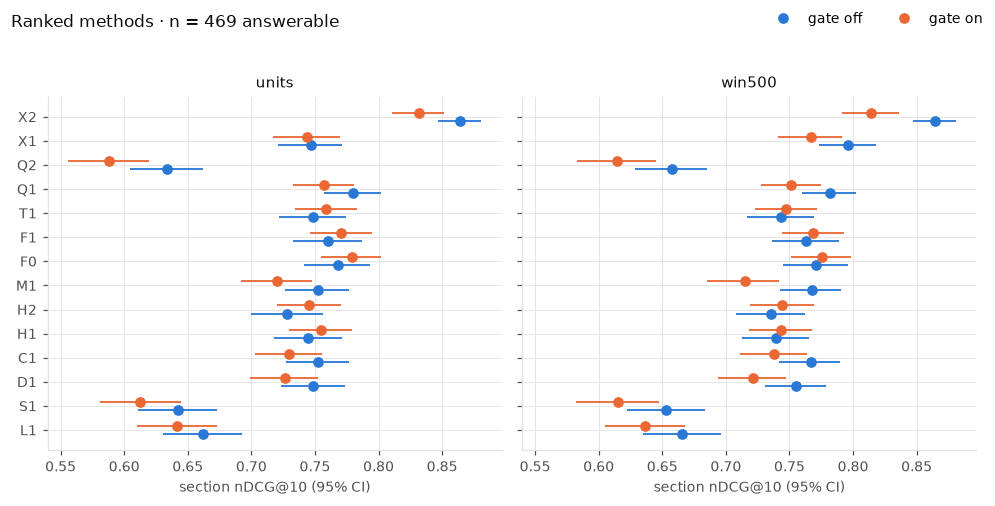

In [12]:
v1 = rt[rt["params_version"] == "v1"]
methods = [m for m in RANKED_METHODS if m in set(v1["method"])]
fig, axes = plt.subplots(1, 2, figsize=(9, 4.6), sharex=True, sharey=True)
for ax, index in zip(axes, corpus.indexes()):
    for j, (gate, label) in enumerate([(False, "gate off"), (True, "gate on")]):
        r = v1[(v1["index"] == index) & (v1["gate"] == gate) & v1["method"].isin(methods)].set_index("method").reindex(methods)
        y = np.arange(len(methods)) + (0.17 if j else -0.17)
        val = metric(r["run_id"], "section", "ndcg@10").values
        lo = metric(r["run_id"], "section", "ndcg@10", "ci_lo").values
        hi = metric(r["run_id"], "section", "ndcg@10", "ci_hi").values
        ax.hlines(y, lo, hi, color=SLOTS[j], linewidth=1.2)
        ax.plot(val, y, "o", color=SLOTS[j], label=label)
    ax.set_yticks(np.arange(len(methods)), methods)
    ax.invert_yaxis()
    ax.set_title(f"{index}")
    ax.set_xlabel("section nDCG@10 (95% CI)")
fig.suptitle(f"Ranked methods · n = {N_ANSWERABLE} answerable", x=0.01, ha="left", color=INK)
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncols=2)
fig.tight_layout(rect=(0, 0, 1, 0.95))

### RQ6: evidence recall within the budget vs context handed over (gate on, v1)

Each line is one expansion method across the 4k / 8k / 16k budgets.

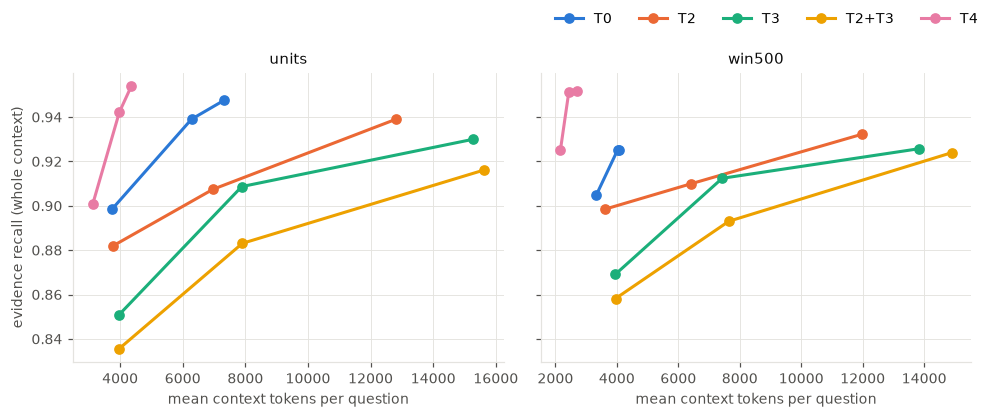

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
for ax, index in zip(axes, corpus.indexes()):
    for j, m in enumerate(EXPANSION_METHODS):
        r = v1[(v1["index"] == index) & v1["gate"] & (v1["method"] == m)].sort_values("budget")
        if r.empty:
            continue
        x = costs.set_index("run_id").loc[r["run_id"], "context_tokens"].values
        y = metric(r["run_id"], "evidence", "evidence_recall@ctx").values
        ax.plot(x, y, "-o", color=SLOTS[j], label=m)
    ax.set_title(index)
    ax.set_xlabel("mean context tokens per question")
axes[0].set_ylabel("evidence recall (whole context)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncols=5)
fig.tight_layout(rect=(0, 0, 1, 0.92))

### RQ7: windows vs units (gate off, v1)

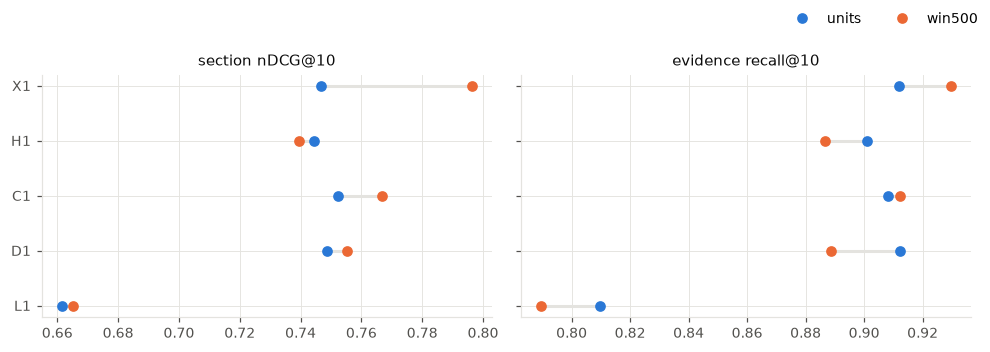

In [14]:
m7 = ["L1", "D1", "C1", "H1", "X1"]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, (level, name, title) in zip(axes, [("section", "ndcg@10", "section nDCG@10"), ("evidence", "evidence_recall@10", "evidence recall@10")]):
    for j, index in enumerate(corpus.indexes()):
        r = v1[(v1["index"] == index) & ~v1["gate"] & v1["method"].isin(m7)].set_index("method").reindex(m7)
        ax.plot(metric(r["run_id"], level, name).values, np.arange(len(m7)), "o", color=SLOTS[j], label=index, zorder=3)
    u = v1[(v1["index"] == "units") & ~v1["gate"] & v1["method"].isin(m7)].set_index("method").reindex(m7)["run_id"]
    w = v1[(v1["index"] == "win500") & ~v1["gate"] & v1["method"].isin(m7)].set_index("method").reindex(m7)["run_id"]
    ax.hlines(np.arange(len(m7)), metric(u, level, name).values, metric(w, level, name).values, color=GRID, linewidth=2, zorder=2)
    ax.set_yticks(np.arange(len(m7)), m7)
    ax.invert_yaxis()
    ax.set_title(title)
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncols=2)
fig.tight_layout(rect=(0, 0, 1, 0.9))

### RQ7 by gold-section length: windows minus units, section nDCG@10 (gate off, v1)

Windows should differ most from base units on long sections.

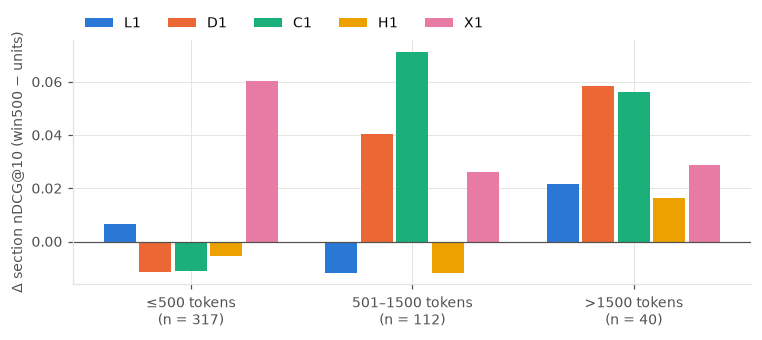

In [15]:
qf = rp._question_frame(questions, corpus).set_index("question_id")
sec = pq[(pq["level"] == "section") & (pq["metric"] == "ndcg@10")].join(qf["length_bucket"], on="question_id")
buckets = ["≤500", "501–1500", ">1500"]
fig, ax = plt.subplots(figsize=(7, 3.2))
width = 0.16
for j, m in enumerate(m7):
    d = []
    for b in buckets:
        ids = {i: v1[(v1["index"] == i) & ~v1["gate"] & (v1["method"] == m)]["run_id"] for i in corpus.indexes()}
        if any(x.empty for x in ids.values()):
            d.append(np.nan)
            continue
        s = {i: sec[(sec["run_id"] == ids[i].iloc[0]) & (sec["length_bucket"] == b)].set_index("question_id")["value"] for i in ids}
        d.append(float((s["win500"] - s["units"]).mean()))
    ax.bar(np.arange(len(buckets)) + (j - 2) * width, d, width * 0.9, color=SLOTS[j], label=m)
ax.axhline(0, color=INK2, linewidth=0.8)
ax.set_xticks(np.arange(len(buckets)), [f"{b} tokens\n(n = {int((qf['length_bucket'] == b).sum())})" for b in buckets])
ax.set_ylabel("Δ section nDCG@10 (win500 − units)")
ax.legend(ncols=5, loc="upper left", bbox_to_anchor=(0, 1.15))
fig.tight_layout()

## Gate diagnostics

Kept length and gate loss per gate position (gate A per signal, gate B after reranking), and the overall gate loss against the gate-off run of the same configuration.

In [16]:
g = gates.merge(rt[["run_id", "method", "index", "budget", "params_version"]], on="run_id")
g = g.merge(gate_overall, on="run_id", how="left")
g.sort_values(["params_version", "index", "method", "position"])[["method", "index", "budget", "position", "in_mean", "kept_mean",
                                                                  "kept_median", "gate_loss", "gate_loss_overall"]].round(3)

,method,index,budget,position,in_mean,kept_mean,kept_median,gate_loss,gate_loss_overall
0,C1,units,NaN,A:colbert,50.000,6.314,5.0,0.075,0.053
2,D1,units,NaN,A:dense,50.000,6.407,5.0,0.070,0.053
4,F0,units,NaN,A:bm25,49.642,6.021,5.0,0.111,0.013
5,F0,units,NaN,A:dense,50.000,6.321,5.0,0.062,0.013
8,F1,units,NaN,A:bm25,49.671,6.059,5.0,0.109,0.013
...,...,...,...,...,...,...,...,...,...
102,X1,win500,NaN,A:dense,50.000,6.673,5.0,0.079,0.045
103,X1,win500,NaN,B:X1,10.451,6.658,7.0,0.023,0.045
107,X2,win500,NaN,A:bm25,49.943,6.218,5.0,0.107,0.036
108,X2,win500,NaN,A:dense,50.000,6.673,5.0,0.079,0.036


## Agent decision paths (T4)

Per question: `stop` (the hits were enough), `expand`, `follow_refs`, `search`, `limit` (step limit reached).

In [17]:
rows = []
for rid in rt[rt["method"] == "T4"]["run_id"]:
    c = runs.load_config(rid)
    for s in runs.load_stats(rid):
        p = s["agent"]["path"]
        kind = "stop at once" if p == ["stop"] else ("step limit" if "limit" in p else "+".join(sorted({x for x in p if x != "stop"})))
        rows.append({"index": c["index"], "budget": c["config"]["expansion"]["budget"], "params": c["params_version"], "path": kind})
if rows:
    display(pd.DataFrame(rows).pivot_table(index="path", columns=["params", "index", "budget"], aggfunc="size", fill_value=0))

params                       v1                               
index                     units             win500            
budget                    4096  8192  16384  4096  8192  16384
path                                                          
expand                        8    10    10     28    32    35
expand+follow_refs            0     0     0      0     1     0
expand+follow_refs+search     0     0     1      2     0     0
expand+search                21    20    11     19    20    17
follow_refs                   2     2     2      5     6     5
follow_refs+search            1     2     0      2     2     2
search                       35    37    33     37    28    27
step limit                    5     6    14      6    13    17
stop at once                405   400   406    378   375   374

## Cost per question

In [18]:
costs.merge(rt, on="run_id").groupby(["params_version", "index", "method"])[
    ["latency_qdrant_s", "latency_encoder_s", "latency_rerank_s", "latency_llm_s", "latency_total_s",
     "llm_prompt_tokens", "llm_completion_tokens", "context_tokens"]].mean().round(2)

latency_qdrant_s  latency_encoder_s  \
params_version index  method                                        
v1             units  C1                  0.79               0.02   
                      D1                  0.00               0.02   
                      F0                  0.00               0.02   
                      F1                  0.00               0.02   
                      H1                  0.01               0.02   
                      H2                  0.01               0.02   
                      L1                  0.00               0.02   
                      M1                  0.07               0.02   
                      Q1                  0.00               0.25   
                      Q2                  0.00               0.02   
                      S1                  0.00               0.02   
                      T0                  0.01               0.02   
                      T1                  0.01               0.02   
                      T2                  0.01               0.02   
                      T2+T3               0.01               0.02   
                      T3                  0.01               0.02   
                      T4                  0.01               0.06   
                      X1                  0.01               0.02   
                      X2                  0.01               0.02   
               win500 C1                  0.75               0.02   
                      D1                  0.00               0.02   
                      F0                  0.00               0.02   
                      F1                  0.00               0.02   
                      H1                  0.01               0.02   
                      H2                  0.01               0.02   
                      L1                  0.00               0.02   
                      M1                  0.08               0.02   
                      Q1                  0.00               0.25   
                      Q2                  0.00               0.02   
                      S1                  0.00               0.02   
                      T0                  0.01               0.02   
                      T1                  0.01               0.02   
                      T2                  0.01               0.02   
                      T2+T3               0.01               0.02   
                      T3                  0.01               0.02   
                      T4                  0.01               0.07   
                      X1                  0.01               0.02   
                      X2                  0.01               0.02   

                              latency_rerank_s  latency_llm_s  \
params_version index  method                                    
v1             units  C1                  0.00           0.00   
                      D1                  0.00           0.00   
                      F0                  0.00           0.00   
                      F1                  0.00           0.95   
                      H1                  0.00           0.00   
                      H2                  0.00           0.00   
                      L1                  0.00           0.00   
                      M1                  0.00           0.00   
                      Q1                  0.00          12.73   
                      Q2                  0.00           4.75   
                      S1                  0.00           0.00   
                      T0                  0.00           0.00   
                      T1                  0.00           0.00   
                      T2                  0.00           0.00   
                      T2+T3               0.00           0.00   
                      T3                  0.00           0.00   
                      T4                  0.00          15.15   
                      X1          

## Unanswerable questions (inspection only, not scored)

In [19]:
un = pd.read_excel(RESULTS / "units" / "metrics.xlsx", sheet_name="unanswerable")
if not N_UNANSWERABLE:
    un = pd.DataFrame(columns=["run_id", "question_id", "top5_sections", "n_distractors_in_top5", "top1_score", "n_hits"])
un[un["run_id"].str.startswith(("H1-", "X1-", "X2-"))][["run_id", "question_id", "top5_sections", "n_distractors_in_top5", "top1_score", "n_hits"]].head(24)

,run_id,question_id,top5_sections,n_distractors_in_top5,top1_score,n_hits
64,H1-units-gateoff-v1-8415d82e,q093,AMC E 570 | CS-E 130 | AMC E 130 | CS-E 570 | ...,2,0.032787,20
65,H1-units-gateoff-v1-8415d82e,q094,CS-E 370 | AMC E 740(c)(3) | CS-E 750 | CS-E 1...,3,0.031754,20
66,H1-units-gateoff-v1-8415d82e,q095,CS-E 900 | CS-E 180 | CS-E 740 | CS-E 750 | AM...,1,0.031778,20
67,H1-units-gateoff-v1-8415d82e,q096,CS-E 1040 | CS-E 800 | CS-E 740 | AMC E 25 | C...,1,0.032787,20
68,H1-units-gateoff-v1-8415d82e,q097,AMC E 470 | AMC E 670 | CS-E 670 | AMC E 30 | ...,2,0.032266,20
69,H1-units-gateoff-v1-8415d82e,q098,AMC E 710 | CS-E 710 | AMC E 910 | CS-E 800 | ...,2,0.032522,20
70,H1-units-gateoff-v1-8415d82e,q099,CS-E 10 | AMC E 80 | AMC E 170 | CS-E 1000 | A...,1,0.032787,20
71,H1-units-gateoff-v1-8415d82e,q100,CS-E 300 | CS-E 260 | CS-E 920 | AMC E 40(d) |...,2,0.032522,20
72,H1-units-gateon-v1-9f5e5fd2,q093,AMC E 570 | CS-E 130 | CS-E 570 | CS-E 25 | CS...,2,0.032787,8
73,H1-units-gateon-v1-9f5e5fd2,q094,CS-E 370 | CS-E 750 | AMC E 740(c)(3) | AMC E ...,3,0.031754,15


## Pipeline diagrams

Picked by hand for the write-up (here: one per RQ). Each is generated from the run's stored config and written to `results/diagrams/<run_id>.md`.

In [20]:
def pick(method, index, gate, budget=None, params_version="v1"):
    r = rt[(rt["method"] == method) & (rt["index"] == index) & (rt["gate"] == gate) & (rt["params_version"] == params_version)]
    if budget is not None:
        r = r[r["budget"] == budget]
    return r["run_id"].iloc[0] if len(r) else None

DIAGRAM_RUNS = [x for x in [
    pick("C1", "units", False),            # RQ1
    pick("H1", "units", True),             # RQ2
    pick("X2", "units", True),             # RQ3
    pick("Q1", "units", False),            # RQ4
    pick("F1", "units", True),             # RQ5
    pick("T4", "units", True, 16384),      # RQ6
    pick("H1", "win500", False),           # RQ7
] if x]
for rid in DIAGRAM_RUNS:
    path = rp.write_diagram(rid, RESULTS / "diagrams", rm=rm, sig=pd.concat([sig, sig7]), gates=gates, costs=costs)
    display(Markdown(path.read_text(encoding="utf-8")))

# C1-units-gateoff-v1-b814c18d

C1: ColBERT MaxSim over all units · index `units` · gate off · params `v1` · config `b814c18d8312`

```mermaid
flowchart LR
  Q(["question"])
  IX[("cse_units_v1<br/>base units")]
  Q --> IX
  S0["ColBERT MaxSim<br/>client, exact<br/>top-50"]
  IX --> S0
  CTX(["final context<br/>k ≤ 20"])
  S0 --> CTX
  subgraph M["metrics"]
    MP["section nDCG@10 0.752 [0.727, 0.777]<br/>Recall@10 0.934<br/>evidence recall@10 0.908<br/>latency 0.81 s/question<br/>n = 469 answerable"]
  end
  CTX -.- MP
```

| comparison | Δ section nDCG@10 | 95% CI | p (Holm) |
|---|---|---|---|
| RQ1 C1 vs L1 | +0.091 | [+0.062, +0.120] | 0.0006 |
| RQ7 C1@win500 vs C1@units | +0.014 | [+0.002, +0.026] | 0.0592 |


# H1-units-gateon-v1-9f5e5fd2

H1: BM25 + dense, RRF · index `units` · gate on · params `v1` · config `9f5e5fd2f264`

```mermaid
flowchart LR
  Q(["question"])
  IX[("cse_units_v1<br/>base units")]
  Q --> IX
  S0["BM25<br/>top-50"]
  IX --> S0
  GA0{"gate A<br/>τ 0.4 δ 0.3<br/>keep 5–50"}
  S0 --> GA0
  S1["bge-m3 dense<br/>top-50"]
  IX --> S1
  GA1{"gate A<br/>τ 0.4 δ 0.3<br/>keep 5–50"}
  S1 --> GA1
  FU["RRF<br/>k = 60"]
  GA0 --> FU
  GA1 --> FU
  CTX(["final context<br/>k ≤ 20"])
  FU --> CTX
  subgraph M["metrics"]
    MP["section nDCG@10 0.755 [0.730, 0.779]<br/>Recall@10 0.946<br/>evidence recall@10 0.937<br/>kept length 6.2 · gate loss 0.113<br/>latency 0.02 s/question<br/>n = 469 answerable"]
  end
  CTX -.- MP
```

| comparison | Δ section nDCG@10 | 95% CI | p (Holm) |
|---|---|---|---|
| RQ2 H1 vs L1 | +0.113 | [+0.095, +0.132] | 0.0008 |
| RQ2 H1 vs D1 | +0.029 | [+0.012, +0.047] | 0.0096 |
| RQ2 H2 vs H1 | -0.009 | [-0.020, +0.001] | 0.2968 |
| RQ3 X1 vs H1 | -0.011 | [-0.028, +0.006] | 0.4216 |
| RQ3 X2 vs H1 | +0.077 | [+0.060, +0.093] | 0.0006 |
| RQ5 F1 vs H1 | +0.016 | [+0.004, +0.027] | 0.0264 |
| RQ5 T1 vs H1 | +0.004 | [+0.001, +0.008] | 0.0460 |


# X2-units-gateon-v1-b3ace7ee

X2: H1 -> jina-reranker-v3 · index `units` · gate on · params `v1` · config `b3ace7eea425`

```mermaid
flowchart LR
  Q(["question"])
  IX[("cse_units_v1<br/>base units")]
  Q --> IX
  S0["BM25<br/>top-50"]
  IX --> S0
  GA0{"gate A<br/>τ 0.4 δ 0.3<br/>keep 5–50"}
  S0 --> GA0
  S1["bge-m3 dense<br/>top-50"]
  IX --> S1
  GA1{"gate A<br/>τ 0.4 δ 0.3<br/>keep 5–50"}
  S1 --> GA1
  FU["RRF<br/>k = 60"]
  GA0 --> FU
  GA1 --> FU
  RR["X2 jina-reranker-v3<br/>top 50 in"]
  FU --> RR
  GB{"gate B<br/>τ 0.2 δ 0.5<br/>keep 5–20"}
  RR --> GB
  CTX(["final context<br/>k ≤ 20"])
  GB --> CTX
  subgraph M["metrics"]
    MP["section nDCG@10 0.831 [0.810, 0.852]<br/>Recall@10 0.948<br/>evidence recall@10 0.945<br/>kept length 6.4 · gate loss 0.113<br/>latency 1.58 s/question<br/>n = 469 answerable"]
  end
  CTX -.- MP
```

| comparison | Δ section nDCG@10 | 95% CI | p (Holm) |
|---|---|---|---|
| RQ3 X2 vs H1 | +0.077 | [+0.060, +0.093] | 0.0006 |
| RQ3 X1 vs X2 | -0.087 | [-0.106, -0.070] | 0.0006 |


# Q1-units-gateoff-v1-73502117

Q1: HyDE (dense) · index `units` · gate off · params `v1` · config `73502117bcc2`

```mermaid
flowchart LR
  Q(["question"])
  QT["Q1 HyDE<br/>Qwen, 1 passage,<br/>mean with question"]
  Q --> QT
  IX[("cse_units_v1<br/>base units")]
  QT --> IX
  S0["bge-m3 dense<br/>top-50"]
  IX --> S0
  CTX(["final context<br/>k ≤ 20"])
  S0 --> CTX
  subgraph M["metrics"]
    MP["section nDCG@10 0.780 [0.757, 0.802]<br/>Recall@10 0.964<br/>evidence recall@10 0.945<br/>latency 12.98 s/question<br/>n = 469 answerable"]
  end
  CTX -.- MP
```

| comparison | Δ section nDCG@10 | 95% CI | p (Holm) |
|---|---|---|---|
| RQ4 Q1 vs D1 | +0.031 | [+0.017, +0.047] | 0.0008 |


# F1-units-gateon-v1-d85f1376

F1: H1 + LLM-extracted engine-type filter · index `units` · gate on · params `v1` · config `d85f1376506a`

```mermaid
flowchart LR
  Q(["question"])
  FL{"filter<br/>engine_type ∈ {x, all}<br/>Qwen JSON"}
  Q --> FL
  IX[("cse_units_v1<br/>base units")]
  FL --> IX
  S0["BM25<br/>top-50"]
  IX --> S0
  GA0{"gate A<br/>τ 0.4 δ 0.3<br/>keep 5–50"}
  S0 --> GA0
  S1["bge-m3 dense<br/>top-50"]
  IX --> S1
  GA1{"gate A<br/>τ 0.4 δ 0.3<br/>keep 5–50"}
  S1 --> GA1
  FU["RRF<br/>k = 60"]
  GA0 --> FU
  GA1 --> FU
  CTX(["final context<br/>k ≤ 20"])
  FU --> CTX
  subgraph M["metrics"]
    MP["section nDCG@10 0.771 [0.746, 0.794]<br/>Recall@10 0.946<br/>evidence recall@10 0.933<br/>kept length 6.2 · gate loss 0.109<br/>latency 0.97 s/question<br/>n = 469 answerable"]
  end
  CTX -.- MP
```

| comparison | Δ section nDCG@10 | 95% CI | p (Holm) |
|---|---|---|---|
| RQ5 F1 vs H1 | +0.016 | [+0.004, +0.027] | 0.0264 |


# T4-b16k-units-gateon-v1-f395387b

T4: H1 -> agentic small-to-big · index `units` · gate on · params `v1` · config `f395387b14d4`

```mermaid
flowchart LR
  Q(["question"])
  IX[("cse_units_v1<br/>base units")]
  Q --> IX
  S0["BM25<br/>top-50"]
  IX --> S0
  GA0{"gate A<br/>τ 0.4 δ 0.3<br/>keep 5–50"}
  S0 --> GA0
  S1["bge-m3 dense<br/>top-50"]
  IX --> S1
  GA1{"gate A<br/>τ 0.4 δ 0.3<br/>keep 5–50"}
  S1 --> GA1
  FU["RRF<br/>k = 60"]
  GA0 --> FU
  GA1 --> FU
  EX["T4 agent<br/>≤5 steps, budget 16384<br/>expand · follow_refs · search · done"]
  FU --> EX
  CTX(["final context<br/>budgeted"])
  EX --> CTX
  subgraph M["metrics"]
    MP["section nDCG@10 0.873 [0.855, 0.891]<br/>Recall@10 0.972<br/>evidence recall@10 0.969<br/>kept length 6.2 · gate loss 0.113<br/>latency 16.31 s/question<br/>n = 469 answerable"]
  end
  CTX -.- MP
```

| comparison | Δ section nDCG@10 | 95% CI | p (Holm) |
|---|---|---|---|
| RQ6 T4 vs T2+T3 | +0.112 | [+0.085, +0.140] | 0.0021 |


# H1-win500-gateoff-v1-9d5dfb15

H1: BM25 + dense, RRF · index `win500` · gate off · params `v1` · config `9d5dfb150d1e`

```mermaid
flowchart LR
  Q(["question"])
  IX[("cse_win500_v1<br/>500-token windows")]
  Q --> IX
  S0["BM25<br/>top-50"]
  IX --> S0
  S1["bge-m3 dense<br/>top-50"]
  IX --> S1
  FU["RRF<br/>k = 60"]
  S0 --> FU
  S1 --> FU
  CTX(["final context<br/>k ≤ 20"])
  FU --> CTX
  subgraph M["metrics"]
    MP["section nDCG@10 0.739 [0.713, 0.766]<br/>Recall@10 0.928<br/>evidence recall@10 0.886<br/>latency 0.02 s/question<br/>n = 469 answerable"]
  end
  CTX -.- MP
```

| comparison | Δ section nDCG@10 | 95% CI | p (Holm) |
|---|---|---|---|
| RQ2 H1 vs L1 | +0.074 | [+0.058, +0.090] | 0.0008 |
| RQ2 H1 vs D1 | -0.016 | [-0.036, +0.004] | 0.5829 |
| RQ2 H2 vs H1 | -0.004 | [-0.015, +0.007] | 0.9267 |
| RQ3 X1 vs H1 | +0.057 | [+0.038, +0.076] | 0.0006 |
| RQ3 X2 vs H1 | +0.125 | [+0.104, +0.146] | 0.0006 |
| RQ5 F1 vs H1 | +0.024 | [+0.012, +0.036] | 0.0008 |
| RQ5 T1 vs H1 | +0.004 | [+0.001, +0.007] | 0.0114 |
| RQ7 H1@win500 vs H1@units | -0.005 | [-0.015, +0.005] | 0.6617 |


## Output checks (plan 8)

* both `metrics.csv` / `metrics.xlsx` pairs and `granularity.csv` match `run_metrics.parquet` (same run count and values);
* each CSV opens cleanly: UTF-8, one header row;
* the `unanswerable` sheet lists every unanswerable question for every run;
* each diagram's stage list matches its run's `config.json`.

In [21]:
nd = rm[(rm["subset"] == "all") & (rm["level"] == "section") & (rm["metric"] == "ndcg@10")].set_index("run_id")["value"]
for index in corpus.indexes():
    t = pd.read_csv(RESULTS / index / "metrics.csv", encoding="utf-8")
    assert len(t) == (rt["index"] == index).sum(), "run count differs"
    assert np.allclose(t.set_index("run_id")["section_ndcg@10"], nd.reindex(t["run_id"]).values, equal_nan=True)
    with open(RESULTS / index / "metrics.csv", encoding="utf-8") as f:
        header = f.readline()
        assert "run_id" in header and all("run_id" not in ln for ln in f), "more than one header row"
    x = pd.ExcelFile(RESULTS / index / "metrics.xlsx")
    assert {"metrics", "by_family", "by_question_type", "by_engine_type", "by_kind", "mentions_section_id", "length_bucket",
            "significance", "gate", "per_question", "unanswerable"} <= set(x.sheet_names)
    xm = pd.read_excel(x, "metrics")
    assert np.allclose(xm.set_index("run_id")["section_ndcg@10"], nd.reindex(xm["run_id"]).values, equal_nan=True)
    if N_UNANSWERABLE:
        un = pd.read_excel(x, "unanswerable")
        assert un.groupby("run_id")["question_id"].nunique().eq(N_UNANSWERABLE).all() and un["run_id"].nunique() == len(t)
g7 = pd.read_csv(RESULTS / "granularity.csv")
assert len(g7) == len(sig7)
assert all(rp.diagram_matches_config(r) for r in DIAGRAM_RUNS)
print("output checks passed")

output checks passed
